**Import libraries and load the dataset**

The Individual Household Electric Power Consumption dataset contains information about minute-level electricity measurements collected from a household in France between December 2006 and November 2010. It includes information on active power, reactive power, voltage, current intensity, and energy consumption across different household appliances. The dataset is used to analyze electricity consumption patterns and

The main goal to use historical household electricity consumption data to predict future electricity usage using supervised machine learning models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from xgboost import XGBRegressor



In [2]:
# Load dataset
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

# Combine Date and Time
df["Date"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

# Set Date as index
df.set_index("Date", inplace=True)

# Drop original Time column
df.drop(columns=["Time"], inplace=True)

# Sort by date
df.sort_index(inplace=True)

# Convert columns to numeric
df = df.apply(pd.to_numeric, errors="coerce")

print(df.head())
print("Dataset Shape:", df.shape)

                     Global_active_power  Global_reactive_power  Voltage  \
Date                                                                       
2006-12-16 17:24:00                4.216                  0.418   234.84   
2006-12-16 17:25:00                5.360                  0.436   233.63   
2006-12-16 17:26:00                5.374                  0.498   233.29   
2006-12-16 17:27:00                5.388                  0.502   233.74   
2006-12-16 17:28:00                3.666                  0.528   235.68   

                     Global_intensity  Sub_metering_1  Sub_metering_2  \
Date                                                                    
2006-12-16 17:24:00              18.4             0.0             1.0   
2006-12-16 17:25:00              23.0             0.0             1.0   
2006-12-16 17:26:00              23.0             0.0             2.0   
2006-12-16 17:27:00              23.0             0.0             1.0   
2006-12-16 17:28:00          

Note that data and time have been combined to one coloumn because the dataset contains electricity readings recorded every minute. Setting the combined timestamp as the index makes it easier to analyze trends, seasonality and forecasting patterns.

**Split Data into Train and Test Sets**

In [3]:
# Select target variable
target = "Global_active_power"

# Split dataset chronologically. 
#This ensures that the data for training and testing is divided early in the process for consistency across different models.

split_index = int(len(df) * 0.8)

train = df.iloc[:split_index].copy()
test = df.iloc[split_index:].copy()

print("Training Shape:", train.shape)
print("Testing Shape:", test.shape)

print("Training Period:", train.index.min(), "to", train.index.max())
print("Testing Period:", test.index.min(), "to", test.index.max())

Training Shape: (1660207, 7)
Testing Shape: (415052, 7)
Training Period: 2006-12-16 17:24:00 to 2010-02-11 15:30:00
Testing Period: 2010-02-11 15:31:00 to 2010-11-26 21:02:00


**Create Lag Features by shifting the data for the training and testing sets**

In [4]:
# Create lag features
lags = [1, 2, 3, 60]

data = df[[target]].copy()

for lag in lags:
    data[f"lag_{lag}"] = data[target].shift(lag)

# Separate features and target
feature_cols = [f"lag_{lag}" for lag in lags]

# Preserve original train/test boundary
train_data = data.iloc[:split_index].dropna()
test_data = data.iloc[split_index:].dropna()

X_train = train_data[feature_cols]
y_train = train_data[target]

X_test = test_data[feature_cols]
y_test = test_data[target]

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print(X_train.head())

Training Features: (1647911, 4)
Testing Features: (400347, 4)
                     lag_1  lag_2  lag_3  lag_60
Date                                            
2006-12-16 18:24:00  2.926  2.934  2.940   4.216
2006-12-16 18:25:00  3.452  2.926  2.934   5.360
2006-12-16 18:26:00  4.870  3.452  2.926   5.374
2006-12-16 18:27:00  4.868  4.870  3.452   5.388
2006-12-16 18:28:00  4.866  4.868  4.870   3.666


The lag features are created using the complete chronological series, then select training and testing rows using the original split boundary. This allows the first test prediction to use historical training observations.

**Perform Seasonal Decomposition**
Note that because the dataset contains minute-level readings, I will aggregate the training data into hourly averages and use a seasonal period of 24 hours.

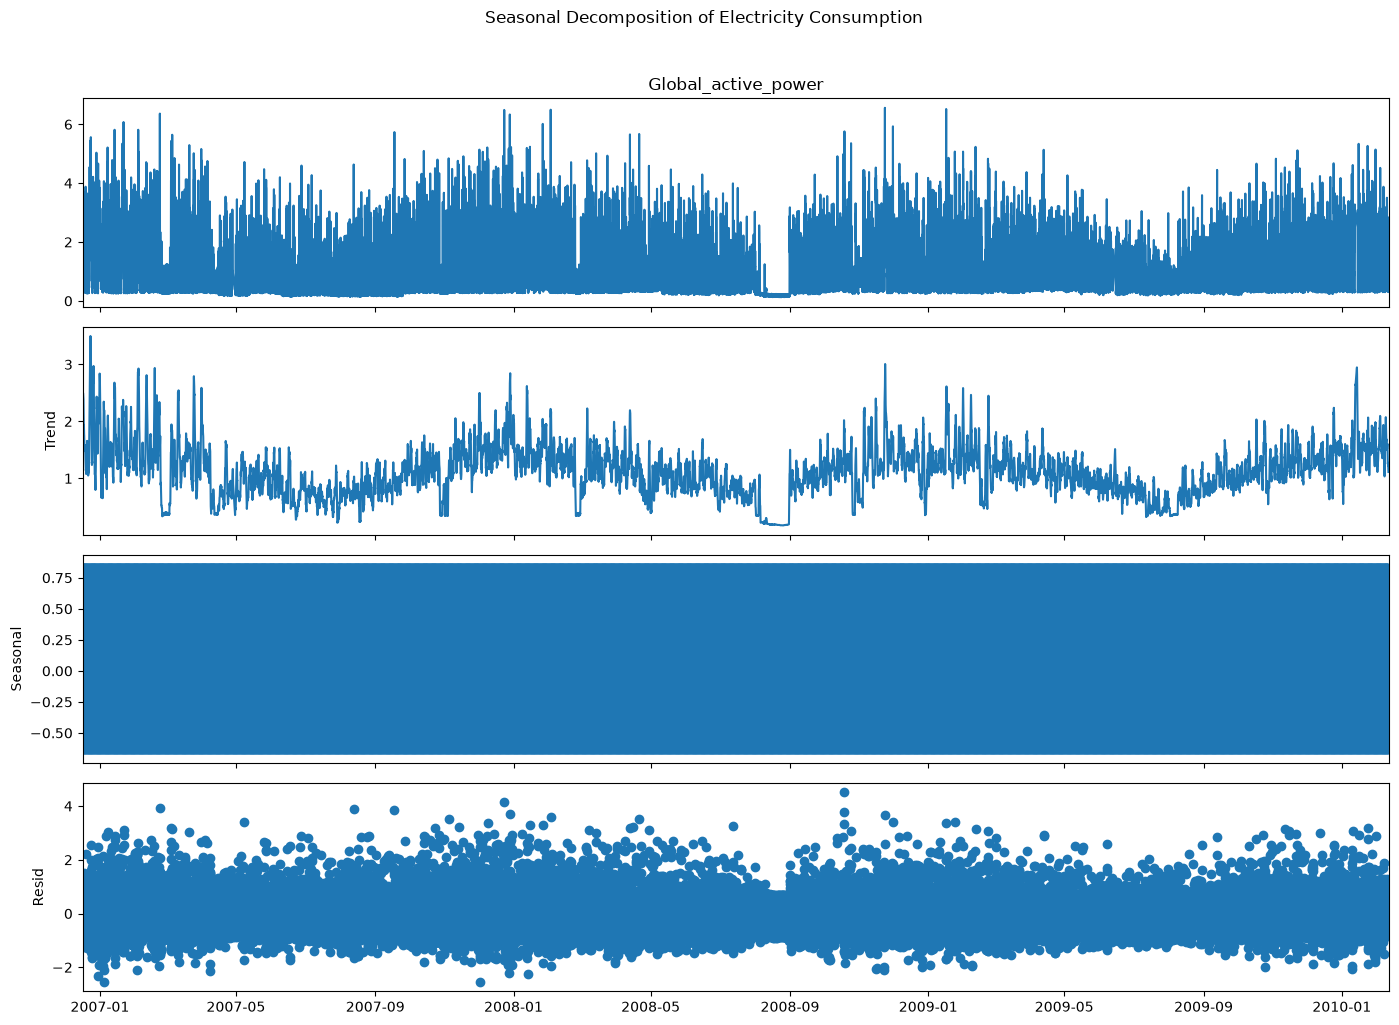

In [5]:
# Use training data only
hourly_power = train[target].resample("h").mean()

# Fill missing hourly values for decomposition
hourly_power = hourly_power.interpolate(
    method="time",
    limit_direction="both"
)

# Seasonal decomposition
decomposition = seasonal_decompose(
    hourly_power,
    model="additive",
    period=24
)

# Plot components
fig = decomposition.plot()
fig.set_size_inches(14, 10)

plt.suptitle(
    "Seasonal Decomposition of Electricity Consumption",
    y=1.02
)

plt.tight_layout()
plt.show()

The trend component shows changes in overall electricity consumption over time. The seasonal component identifies recurring daily consumption patterns, while the residual component captures irregular variations not explained by trend or seasonality. This helps us understand the time-dependent structure of the data before building forecasting models.

**Linear Regression for Time Series Forecasting**

In [6]:
# Initialize Linear Regression
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

# Make predictions
lr_pred = lr_model.predict(X_test)

# Evaluate model
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_pred)

print("Linear Regression Results")
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R² Score:", lr_r2)

Linear Regression Results
MSE: 0.047884650852372555
RMSE: 0.2188256174499973
R² Score: 0.9393139585721627


**Visualize Predictions vs. Actual Values**

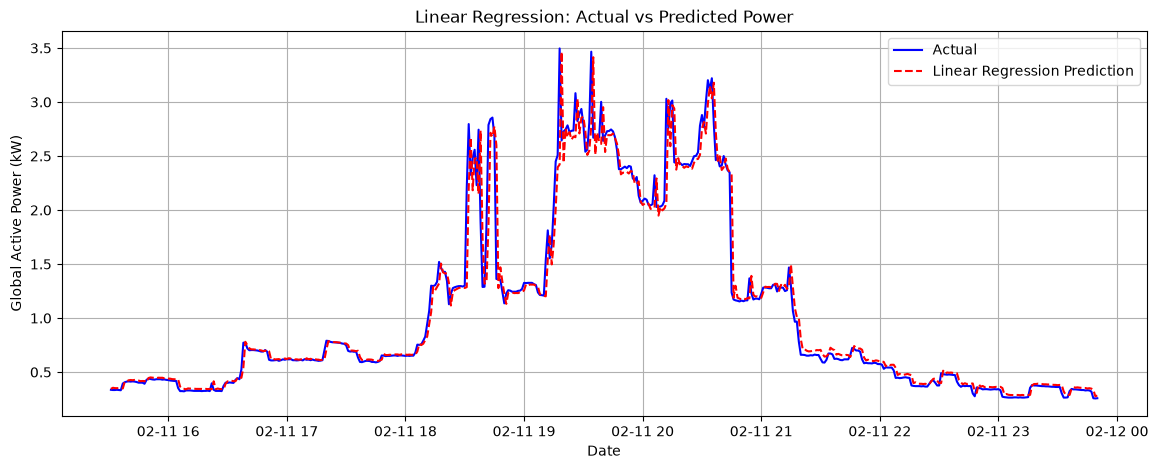

In [9]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index[:500],
    y_test.iloc[:500],
    label="Actual",
    color="blue"
)

plt.plot(
    y_test.index[:500],
    lr_pred[:500],
    label="Linear Regression Prediction",
    color="red",
    linestyle="--"
)

plt.title("Linear Regression: Actual vs Predicted Power")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.show()

The Linear Regression uses historical electricity consumption values to predict future consumption. A lower MSE of $0.048 indicates better predictive performance, while an R² score closer to 1 at 0.939 indicates that the model explains more variation in electricity consumption.



**Train a Random Forest model**

In [10]:
# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluate model
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)

Random Forest Results
MSE: 0.04498087449373292
RMSE: 0.21208695031456537
R² Score: 0.942994024924549


**Visualize Predictions vs. Actual Values**

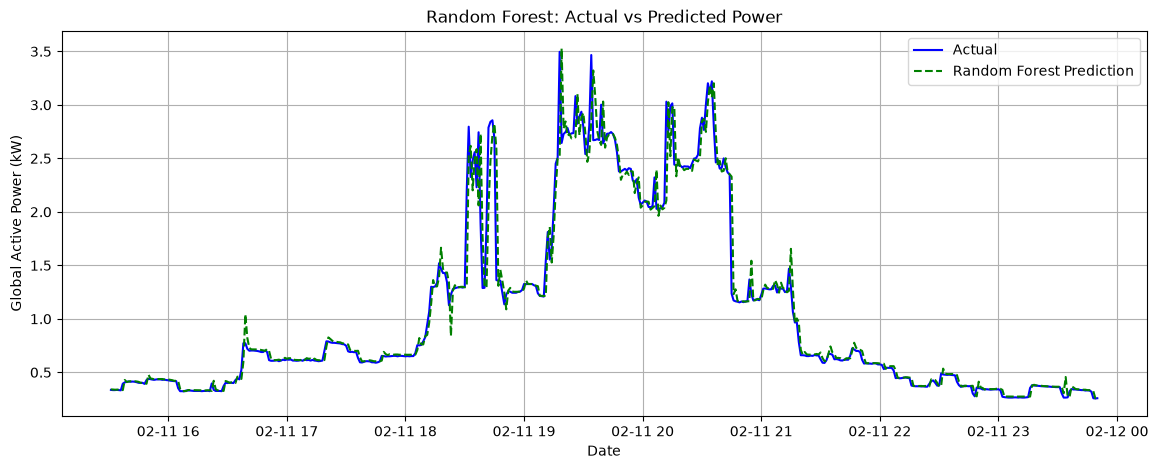

In [11]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index[:500],
    y_test.iloc[:500],
    label="Actual",
    color="blue"
)

plt.plot(
    y_test.index[:500],
    rf_pred[:500],
    label="Random Forest Prediction",
    color="green",
    linestyle="--"
)

plt.title("Random Forest: Actual vs Predicted Power")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.show()

The Random Forest captures nonlinear relationships and interactions between lag features that Linear Regression may miss. A lower MSE of 0.045 indicates better forecasting accuracy on the test set while an R² score closer to 1 at 0.943 indicates that the model explains more variation in electricity consumption. However, the Linear regression model performed better in this score.


**Implement Gradient Boosting (XGBoost)**

In [12]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\tebos\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [13]:
from xgboost import XGBRegressor

# Initialize XGBoost
xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train, y_train)

# Make predictions
xgb_pred = xgb_model.predict(X_test)

# Evaluate model
xgb_mse = mean_squared_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(xgb_mse)
xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost Results")
print("MSE:", xgb_mse)
print("RMSE:", xgb_rmse)
print("R² Score:", xgb_r2)

XGBoost Results
MSE: 0.04586947909625787
RMSE: 0.21417161132199072
R² Score: 0.9418678624745387


** Visualize Predictions vs. Actual Values**

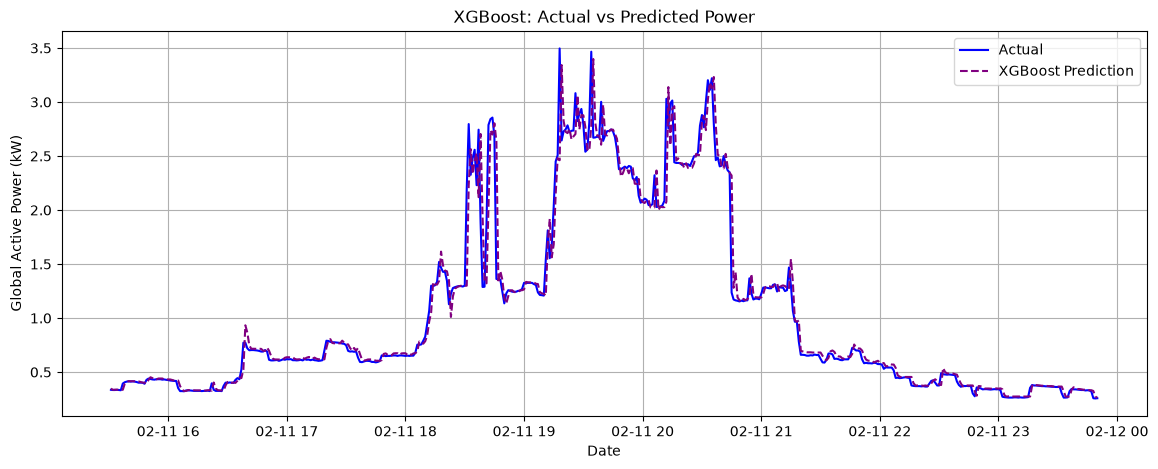

In [14]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index[:500],
    y_test.iloc[:500],
    label="Actual",
    color="blue"
)

plt.plot(
    y_test.index[:500],
    xgb_pred[:500],
    label="XGBoost Prediction",
    color="purple",
    linestyle="--"
)

plt.title("XGBoost: Actual vs Predicted Power")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.show()

The XGBoost builds decision trees sequentially, with each new tree correcting errors made by previous trees. It also identify complex patterns in electricity consumption and produces more accurate forecasts than Linear Regression and Random Forest. 
The XGBoost demonstrated excellent predictive performance, explaining approximately 94.19% of the variation in electricity consumption. Its performance was very close to Random Forest, with only a slightly higher prediction error.

**Compare Model Performances**

In [15]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MSE": [
        lr_mse,
        rf_mse,
        xgb_mse
    ],
    "RMSE": [
        lr_rmse,
        rf_rmse,
        xgb_rmse
    ],
    "R² Score": [
        lr_r2,
        rf_r2,
        xgb_r2
    ]
})

# Sort models by MSE
results = results.sort_values("MSE")

print(results)

               Model       MSE      RMSE  R² Score
1      Random Forest  0.044981  0.212087  0.942994
2            XGBoost  0.045869  0.214172  0.941868
0  Linear Regression  0.047885  0.218826  0.939314


All three models performed very well in predicting household electricity consumption, achieving R² scores above 93% and relatively low prediction errors.

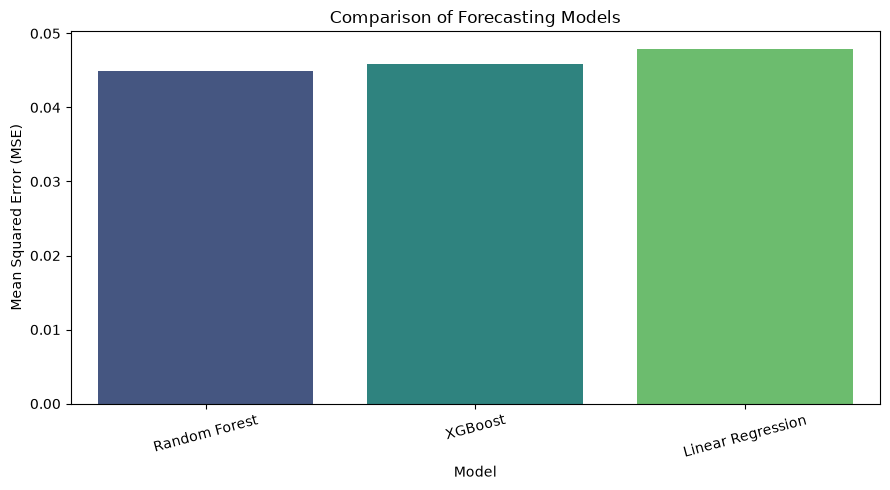

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x="Model",
    y="MSE",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Comparison of Forecasting Models")
plt.xlabel("Model")
plt.ylabel("Mean Squared Error (MSE)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Random Forest was the most accurate forecasting model based on the test results, while Linear Regression remained a competitive and simpler alternative. These findings demonstrate the effectiveness of using lag features and supervised learning algorithms for short-term electricity consumption forecasting.